In [3]:
from pathlib import Path
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

root = Path.cwd().resolve()

if root.name.lower() == "notebooks":
    root = root.parent

data_dir = root / "datasets"
split_file = root / "shared" / "split.csv"
output_dir = root / "outputs" / "preprocessing"
common_dir = root / "common"

output_dir.mkdir(parents=True, exist_ok=True)
common_dir.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(root))

print("Project root:", root)
print("Dataset exists:", data_dir.exists())
print("Split file exists:", split_file.exists())
print("Output directory:", output_dir)

assert split_file.exists(), "Check the project path and shared/split.csv"

Project root: C:\Users\niran\Documents\Brain_Tumour_Project
Dataset exists: True
Split file exists: True
Output directory: C:\Users\niran\Documents\Brain_Tumour_Project\outputs\preprocessing


In [4]:
df = pd.read_csv(split_file)

print("CSV columns:", df.columns.tolist())
display(df.head())

# Adjust these names if your CSV uses different column names.
FILENAME_COL = "filename"
SPLIT_COL = "split"

assert FILENAME_COL in df.columns, "Check the filename column name"
assert SPLIT_COL in df.columns, "Check the split column name"

print(df[SPLIT_COL].value_counts())

CSV columns: ['filename', 'label', 'split']


,filename,label,split
0,Training\glioma\Tr-gl_1.jpg,glioma,train
1,Training\glioma\Tr-gl_10.jpg,glioma,train
2,Training\glioma\Tr-gl_100.jpg,glioma,train
3,Training\glioma\Tr-gl_1000.jpg,glioma,train
4,Training\glioma\Tr-gl_1001.jpg,glioma,train


split
train    4361
test     1598
val       754
Name: count, dtype: int64


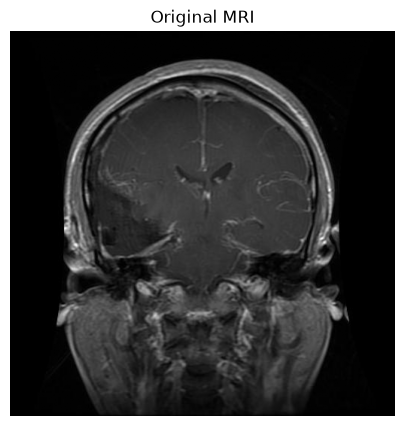

Shape: (512, 512)
Intensity range: 0.0 1.0


In [5]:
def resolve_image_path(filename):
    filename = str(filename).replace("\\", "/")
    relative = Path(filename)

    candidates = [
        root / relative,
        data_dir / relative,
    ]

    # Support paths that begin with datasets/
    if relative.parts and relative.parts[0].lower() == "datasets":
        candidates.append(root.joinpath(*relative.parts[1:]))

    for path in candidates:
        if path.is_file():
            return path

    raise FileNotFoundError(
        f"Could not locate {filename}. Check the CSV path and dataset folders."
    )


def load_mri_image(filename):
    path = resolve_image_path(filename)

    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Unable to read image: {path}")

    return image.astype(np.float32) / 255.0


sample_image = load_mri_image(df.iloc[0][FILENAME_COL])

plt.figure(figsize=(5, 5))
plt.imshow(sample_image, cmap="gray", vmin=0, vmax=1)
plt.title("Original MRI")
plt.axis("off")
plt.show()

print("Shape:", sample_image.shape)
print("Intensity range:", sample_image.min(), sample_image.max())

In [6]:
#preprocessing steps as functions
def validate_image(image):
    image = np.asarray(image, dtype=np.float32)

    if image.ndim != 2:
        raise ValueError("Expected a grayscale image.")

    if not np.isfinite(image).all():
        raise ValueError("Image contains invalid values.")

    if image.max() > 1:
        image = image / 255.0

    return np.clip(image, 0, 1)


def apply_clahe(image, clip_limit=2.0):
    image = validate_image(image)
    image_u8 = np.round(image * 255).astype(np.uint8)

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=(8, 8)
    )

    return clahe.apply(image_u8).astype(np.float32) / 255.0


def apply_gaussian(image, kernel_size=5, sigma=0):
    image = validate_image(image)

    result = cv2.GaussianBlur(
        image, (kernel_size, kernel_size), sigmaX=sigma
    )

    return np.clip(result, 0, 1)


def apply_median(image, kernel_size=3):
    image = validate_image(image)
    image_u8 = np.round(image * 255).astype(np.uint8)

    result = cv2.medianBlur(image_u8, kernel_size)

    return result.astype(np.float32) / 255.0


def apply_unsharp_mask(image, amount=0.5, sigma=1.0):
    image = validate_image(image)

    blurred = cv2.GaussianBlur(
        image, (0, 0), sigmaX=sigma
    )

    sharpened = image + amount * (image - blurred)

    return np.clip(sharpened, 0, 1)

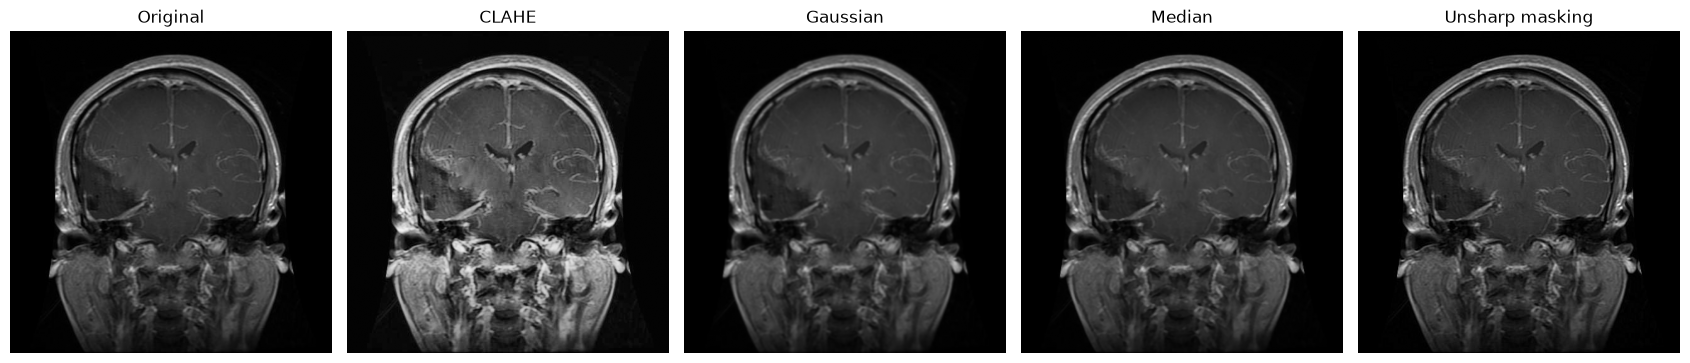

In [7]:
#test for an image
individual_results = {
    "Original": sample_image,
    "CLAHE": apply_clahe(sample_image),
    "Gaussian": apply_gaussian(sample_image),
    "Median": apply_median(sample_image),
    "Unsharp masking": apply_unsharp_mask(sample_image),
}

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for ax, (name, image) in zip(axes, individual_results.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
#quality metrices
def measure_quality(image):
    image = validate_image(image)

    # Global contrast
    contrast = float(np.std(image))

    # Robust estimate of high-frequency noise
    blurred = cv2.GaussianBlur(image, (3, 3), 0)
    residual = image - blurred

    noise = float(
        1.4826 * np.median(
            np.abs(residual - np.median(residual))
        )
    )

    # Sharpness proxy
    laplacian = cv2.Laplacian(image, cv2.CV_32F)
    sharpness = float(np.var(laplacian))

    return {
        "contrast": contrast,
        "noise": noise,
        "sharpness": sharpness,
    }


quality_test = pd.DataFrame([
    {"method": name, **measure_quality(image)}
    for name, image in individual_results.items()
])

display(quality_test.round(5))

,method,contrast,noise,sharpness
0,Original,0.14384,0.00145,0.00105
1,CLAHE,0.22154,0.00436,0.00297
2,Gaussian,0.14050,0.00066,0.00027
3,Median,0.14246,0.00145,0.00089
4,Unsharp masking,0.14575,0.00220,0.00169


In [9]:
#final adaptive pipeline
def fixed_preprocess(image):
    result = apply_clahe(image)
    result = apply_median(result, kernel_size=3)
    result = apply_unsharp_mask(result, amount=0.5)

    return result

In [10]:
def normalize_split(value):
    value = str(value).strip().lower()

    aliases = {
        "training": "train",
        "train": "train",
        "validation": "validation",
        "valid": "validation",
        "val": "validation",
        "testing": "test",
        "test": "test",
    }

    return aliases.get(value, value)


df["_split_normalized"] = df[SPLIT_COL].map(normalize_split)

train_df = df[df["_split_normalized"] == "train"].copy()

assert not train_df.empty, (
    "No training rows detected. Inspect the split values in shared/split.csv."
)

calibration_df = train_df.head(min(500, len(train_df)))

calibration_rows = []

for _, row in calibration_df.iterrows():
    image = load_mri_image(row[FILENAME_COL])

    calibration_rows.append({
        "filename": row[FILENAME_COL],
        **measure_quality(image),
    })

calibration_metrics = pd.DataFrame(calibration_rows)

contrast_threshold = calibration_metrics["contrast"].quantile(0.25)
noise_threshold = calibration_metrics["noise"].quantile(0.75)
sharpness_threshold = calibration_metrics["sharpness"].quantile(0.25)

print("Calibration images:", len(calibration_metrics))
print("Contrast threshold:", contrast_threshold)
print("Noise threshold:", noise_threshold)
print("Sharpness threshold:", sharpness_threshold)

Calibration images: 500
Contrast threshold: 0.13575222715735435
Noise threshold: 0.0018169281538575888
Sharpness threshold: 0.0005936163215665147


In [12]:
#final adaptive pipeline
def adaptive_preprocess(
    image,
    contrast_threshold,
    noise_threshold,
    sharpness_threshold,
):
    result = validate_image(image)
    operations = []

    quality = measure_quality(result)

    if quality["contrast"] < contrast_threshold:
        result = apply_clahe(result)
        operations.append("CLAHE")

    quality = measure_quality(result)

    if quality["noise"] > noise_threshold:
        result = apply_median(result, kernel_size=3)
        operations.append("Median filtering")

    quality = measure_quality(result)

    if quality["sharpness"] < sharpness_threshold:
        result = apply_unsharp_mask(result, amount=0.5)
        operations.append("Unsharp masking")

    if not operations:
        operations.append("No change")

    return result, operations

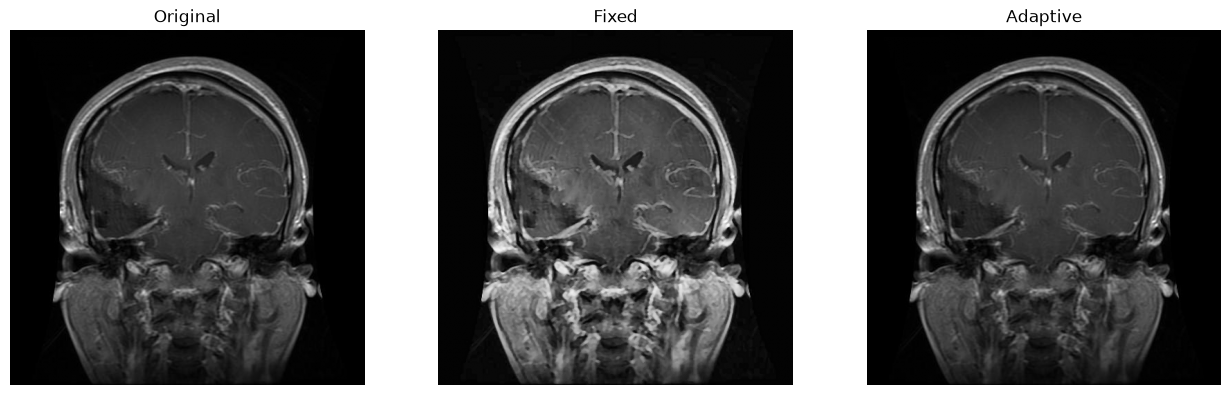

Adaptive operations: ['No change']


In [13]:
#comparison
fixed_image = fixed_preprocess(sample_image)

adaptive_image, applied_operations = adaptive_preprocess(
    sample_image,
    contrast_threshold,
    noise_threshold,
    sharpness_threshold,
)

comparison = {
    "Original": sample_image,
    "Fixed": fixed_image,
    "Adaptive": adaptive_image,
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (name, image) in zip(axes, comparison.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Adaptive operations:", applied_operations)

In [14]:
#dataset level comparison
MAX_IMAGES = 100

experiment_df = train_df.copy()

if MAX_IMAGES is not None:
    experiment_df = experiment_df.head(MAX_IMAGES)

records = []

for i, (_, row) in enumerate(experiment_df.iterrows(), start=1):
    original = load_mri_image(row[FILENAME_COL])

    fixed = fixed_preprocess(original)

    adaptive, operations = adaptive_preprocess(
        original,
        contrast_threshold,
        noise_threshold,
        sharpness_threshold,
    )

    for method, image in [
        ("Original", original),
        ("Fixed", fixed),
        ("Adaptive", adaptive),
    ]:
        records.append({
            "filename": row[FILENAME_COL],
            "split": row[SPLIT_COL],
            "method": method,
            **measure_quality(image),
            "adaptive_operations": (
                "; ".join(operations) if method == "Adaptive" else ""
            ),
        })

    if i % 25 == 0:
        print(f"Processed {i}/{len(experiment_df)} images")

quality_results = pd.DataFrame(records)

quality_results.to_csv(
    output_dir / "quality_metrics.csv",
    index=False,
)

display(quality_results.head())

Processed 25/100 images
Processed 50/100 images
Processed 75/100 images
Processed 100/100 images


,filename,split,method,contrast,noise,sharpness,adaptive_operations
0,Training\glioma\Tr-gl_1.jpg,train,Original,0.143842,0.001454,0.001046,
1,Training\glioma\Tr-gl_1.jpg,train,Fixed,0.222713,0.004010,0.004202,
2,Training\glioma\Tr-gl_1.jpg,train,Adaptive,0.143842,0.001454,0.001046,No change
3,Training\glioma\Tr-gl_10.jpg,train,Original,0.174388,0.003634,0.001134,
4,Training\glioma\Tr-gl_10.jpg,train,Fixed,0.240591,0.007639,0.004959,


,contrast,noise,sharpness
method,,,
Original,0.15094,0.00125,0.00077
Fixed,0.21563,0.00307,0.00320
Adaptive,0.16684,0.00142,0.00111


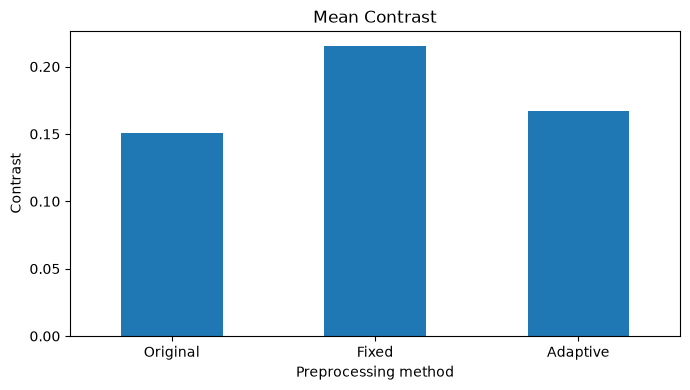

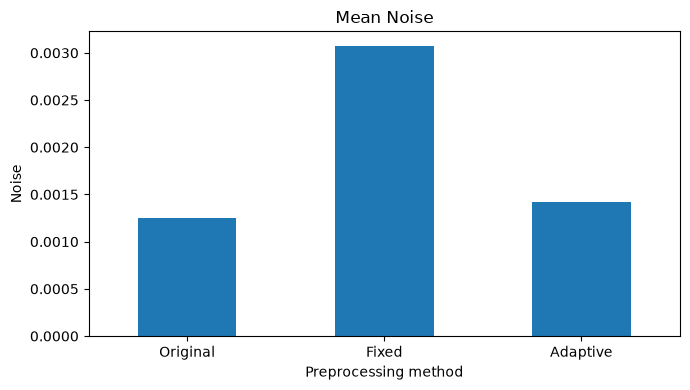

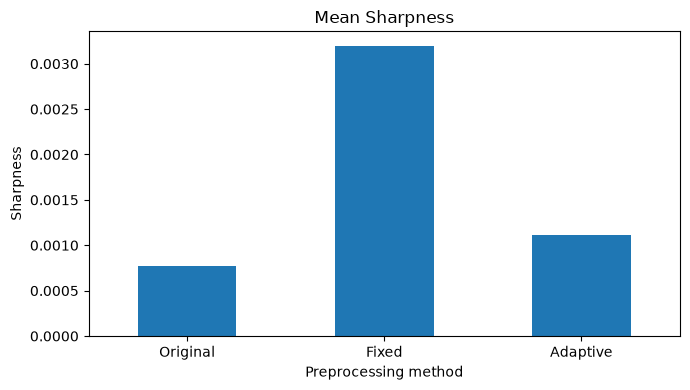

In [15]:
#saving graphs and before/after image
metric_names = ["contrast", "noise", "sharpness"]

summary = (
    quality_results
    .groupby("method")[metric_names]
    .mean()
    .reindex(["Original", "Fixed", "Adaptive"])
)

summary.to_csv(output_dir / "quality_summary.csv")

display(summary.round(5))

for metric in metric_names:
    ax = summary[metric].plot(kind="bar", figsize=(7, 4))

    ax.set_title(f"Mean {metric.capitalize()}")
    ax.set_xlabel("Preprocessing method")
    ax.set_ylabel(metric.capitalize())

    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        output_dir / f"{metric}_comparison.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

In [17]:
#saving the functions for future usage
import inspect

function_names = [
    "validate_image",
    "apply_clahe",
    "apply_gaussian",
    "apply_median",
    "apply_unsharp_mask",
    "measure_quality",
    "fixed_preprocess",
    "adaptive_preprocess",
]

module_parts = [
    '"""Reusable DIP preprocessing functions for brain MRI images."""',
    "import cv2",
    "import numpy as np",
    "",
    f"DEFAULT_THRESHOLDS = {dict(contrast_threshold=float(contrast_threshold), noise_threshold=float(noise_threshold), sharpness_threshold=float(sharpness_threshold))!r}",
    "",
]

for name in function_names:
    module_parts.append(inspect.getsource(globals()[name]))
    module_parts.append("")

module_path = common_dir / "preprocess.py"
module_path.write_text("\n".join(module_parts), encoding="utf-8")

print("Reusable module saved:", module_path)

Reusable module saved: C:\Users\niran\Documents\Brain_Tumour_Project\common\preprocess.py
